# Operators as sums of Pauli strings

Every application in Unit 3 starts by writing the problem as an operator. In
the traveling-salesman and protein-folding notebooks the operator scores every
possible answer, a bitstring, by its cost. In the molecule and nucleus
notebooks it is the energy of the particles. Either way the operator is a
large matrix, and a quantum computer cannot be handed a matrix directly. It
can apply and measure products of the one-qubit operators $I$, $X$, $Y$ and
$Z$.

So this notebook asks: can every operator be written as a weighted sum of
such products, and how do we find the weights? And how does a cost function
of ordinary bits, the kind Notebook 03 wrote for one-hot encodings, become
such an operator?

## Before you start

This notebook uses:

- bitstrings and the tensor product ([Notebook 00](00_Bits_and_Basis_States.ipynb));
- the number operator $n = a^\dagger a$ (the projector onto $|1\rangle$),
  with $n|x\rangle = x|x\rangle$ and $n = (I - Z)/2$, and the Pauli operators
  $X$ and $Z$ ([Notebook 01](01_One_Bit_Operators.ipynb));
- the subscript notation $A_k$, the tensor product of operators, operators
  that commute ($AB = BA$), CX, and the hopping terms of SWAP
  ([Notebook 02](02_Reversible_Logic.ipynb));
- one-hot encodings and penalties, and the rule $x^2 = x$ for a bit
  ([Notebook 03](03_Encodings.ipynb));
- the Pauli operator $Y$, the conjugate transpose $M^\dagger$ and the rule
  $(AB)^\dagger = B^\dagger A^\dagger$, superpositions, the Born rule for
  several qubits, and $H$ ([Notebook 04](04_Amplitudes_and_Phase.ipynb));
- the parity operator $Z_1 Z_0$ and the rule that Pauli operators square to
  $I$ ([Notebook 07](07_Rotations.ipynb)).

From linear algebra it uses the trace $\mathrm{tr}(M)$, the sum of the
diagonal entries, and its property $\mathrm{tr}(AB) = \mathrm{tr}(BA)$.

Quick check:

1. What is the trace of $\left(\begin{smallmatrix}2&1\\1&0\end{smallmatrix}\right)$?
2. What are $n|0\rangle$ and $n|1\rangle$?
3. For a bit $x$, why is $x^2 = x$?

Answers: $2$; $0$ and $|1\rangle$; because $0^2 = 0$ and $1^2 = 1$.

After this notebook you will be able to:

1. Write a given $2\times2$ or $4\times4$ matrix as a weighted sum of tensor
   products of $I$, $X$, $Y$ and $Z$.
2. Turn a cost function of bits into an operator whose eigenvector with the
   lowest eigenvalue is the cheapest bitstring.
3. Explain why, for some operators, the eigenvector with the lowest
   eigenvalue is a superposition and not a single bitstring.
4. Build these operators in Qiskit and read off their eigenvalues.

## Setup

The same setup as every notebook in this unit.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# Aer, and IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit
    precision=0.02,              # used from Notebook 09 on
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## Pauli strings

On one qubit we have four operators with simple matrices:

$$I = \begin{pmatrix}1&0\\0&1\end{pmatrix},\quad X = \begin{pmatrix}0&1\\1&0\end{pmatrix},\quad Y = \begin{pmatrix}0&-i\\i&0\end{pmatrix},\quad Z = \begin{pmatrix}1&0\\0&-1\end{pmatrix}.$$

On several qubits, combine them with the tensor product, one factor per
qubit. A *Pauli string* is a tensor product with one of $I$, $X$, $Y$, $Z$ on
each qubit, such as $Z_1 Z_0 = Z \otimes Z$ or $X_1 = X \otimes I$. In words: a
Pauli string says, for every qubit, which of the four one-qubit operators acts
on it. On $n$ qubits there are $4^n$ Pauli strings, because each qubit has
four choices.

Qiskit writes a Pauli string as a *label*, a text string with one letter per
qubit. **The rightmost letter acts on qubit 0**, the same order as bitstrings.
So `"ZI"` is $Z_1$ (a $Z$ on qubit 1 and nothing on qubit 0) and `"IZ"` is
$Z_0$. Reading a label the other way around is a mistake Qiskit cannot
catch: it gives no error message, only wrong numbers.

In code, `SparsePauliOp("ZI")` builds the operator with label `"ZI"`, and its
method `to_matrix()` returns the matrix. The cell below uses them to confirm
the letter order. The section on the Pauli decomposition says more about
`SparsePauliOp`.

Two Pauli strings multiply qubit by qubit. On one qubit the products of two
different non-identity Paulis are

$$XY = iZ,\qquad YZ = iX,\qquad ZX = iY,$$

and reversing the order flips the sign ($YX = -iZ$, and so on). Each Pauli
squared is $I$ (Notebook 07). So the product of two Pauli strings is always
another Pauli string times $1$, $-1$, $i$ or $-i$.

In [2]:
I2 = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.diag([1, -1])

xy = np.allclose(X @ Y, 1j * Z)
yz = np.allclose(Y @ Z, 1j * X)
zx = np.allclose(Z @ X, 1j * Y)
print("XY == iZ:", xy, "  YZ == iX:", yz, "  ZX == iY:", zx)
zi = SparsePauliOp("ZI").to_matrix()
print("label 'ZI' is Z on qubit 1:", np.allclose(zi, np.kron(Z, I2)))

XY == iZ: True   YZ == iX: True   ZX == iY: True
label 'ZI' is Z on qubit 1: True


**Check.** Which Qiskit label is $X_2 Z_0$ on three qubits?

## The Pauli decomposition

Can every $2\times2$ matrix be written as $c_I I + c_X X + c_Y Y + c_Z Z$?
Count unknowns: four numbers $c_P$ for four matrix entries, so it is at least
plausible. Here is a concrete case:

$$\begin{pmatrix}2&1\\1&0\end{pmatrix} = I + X + Z,$$

since $I + Z = \mathrm{diag}(2, 0)$ and $X$ supplies the two off-diagonal 1s.
Guessing works for small cases. A formula works for all of them.

The *Pauli decomposition* of an $n$-qubit matrix $M$ (size $2^n \times 2^n$)
is

$$M = \sum_P c_P\, P, \qquad c_P = \frac{\mathrm{tr}(P M)}{2^n},$$

where the sum runs over all $4^n$ Pauli strings $P$. In words: the weight of
each Pauli string is the trace of that string times $M$, divided by the size
of the matrix. Every matrix has exactly one such decomposition.

Why the formula holds: the trace of a product of two Pauli strings is $2^n$
when they are equal and 0 otherwise.

- On one qubit, $\mathrm{tr}(PP) = \mathrm{tr}(I) = 2$. If $P \ne Q$, then
  $PQ$ is $\pm i$ times a non-identity Pauli (from the products above), or a
  non-identity Pauli itself when one of them is $I$. Every non-identity Pauli
  has trace 0.
- On $n$ qubits, the trace of a tensor product is the product of the traces,
  $\mathrm{tr}(A \otimes B) = \mathrm{tr}(A)\,\mathrm{tr}(B)$: the diagonal
  blocks of $A \otimes B$ are $a_{ii} B$, and each contributes
  $a_{ii}\,\mathrm{tr}(B)$. By the mixed-product rule of Notebook 02,
  $PQ$ is the tensor product of the one-qubit products, so
  $\mathrm{tr}(PQ)$ is $2 \cdot 2 \cdots 2 = 2^n$ when every factor matches and
  0 as soon as one factor differs.

Now multiply $M = \sum_Q c_Q Q$ on the left by one string $P$ and take the
trace. Every term with $Q \ne P$ drops out, which leaves
$\mathrm{tr}(PM) = 2^n c_P$. So if a decomposition exists, its coefficients
are fixed by the formula, and there is only one.

Why one always exists: the same argument shows that the $4^n$ Pauli strings
are linearly independent, since if $\sum_Q c_Q Q = 0$, the trace with each
$P$ gives $c_P = 0$. The $2^n \times 2^n$ matrices form a vector space of
dimension $(2^n)^2 = 4^n$, one dimension per entry. A set of $4^n$ linearly
independent matrices in that space is a basis, so every matrix is a
combination of Pauli strings.

### Example 1: $a$, $a^\dagger$ and $n$ as Pauli sums

**Problem.** Find the Pauli decompositions of $a = \left(\begin{smallmatrix}0&1\\0&0\end{smallmatrix}\right)$,
$a^\dagger$, and $n = a^\dagger a$.

**Plan.** Compute the four traces $\mathrm{tr}(Pa)$ and divide by $2^1 = 2$.
Then get $a^\dagger$ from $a$, and $n$ the same way.

**Solution.**

**Subgoal 1: the coefficients of $a$.**

1. $c_I = \mathrm{tr}(a)/2 = 0$, since both diagonal entries of $a$ are 0.
2. Multiply: $Xa = \left(\begin{smallmatrix}0&0\\0&1\end{smallmatrix}\right)$, trace 1, so $c_X = 1/2$.
3. Multiply: $Ya = \left(\begin{smallmatrix}0&0\\0&i\end{smallmatrix}\right)$, trace $i$, so $c_Y = i/2$.
4. Multiply: $Za = \left(\begin{smallmatrix}0&1\\0&0\end{smallmatrix}\right)$, trace 0, so $c_Z = 0$.
5. So $a = (X + iY)/2$.

**Subgoal 2: $a^\dagger$.**

6. Take the conjugate transpose of both sides. $X$ and $Y$ each equal their
   own conjugate transpose, and the coefficient $i$ becomes $-i$:
   $a^\dagger = (X - iY)/2$.

**Subgoal 3: $n$.**

7. $n = \mathrm{diag}(0, 1)$, so $c_I = \mathrm{tr}(n)/2 = 1/2$ and
   $c_Z = \mathrm{tr}(Zn)/2 = -1/2$. $Xn$ and $Yn$ have zeros on the diagonal,
   so $c_X = c_Y = 0$.
8. So $n = (I - Z)/2$.

**Check.** Add the matrices: $X + iY = \left(\begin{smallmatrix}0&1+1\\1-1&0\end{smallmatrix}\right) = \left(\begin{smallmatrix}0&2\\0&0\end{smallmatrix}\right)$,
and half of that is $a$. The result $n = (I - Z)/2$ is the relation Notebook 01
found from $Z = I - 2n$.

**Self-explanation prompt.** Why does $a$ need a complex coefficient while $n$
does not? **Answer.** $a$ is not equal to its own conjugate transpose, while
$n$ is, and the next paragraph shows that a matrix has all-real Pauli
coefficients exactly when it equals its own conjugate transpose.

**Takeaway.** Creation and annihilation are each half of $X$ plus or minus
$i$ times half of $Y$. Products of them, such as $n$, give Pauli sums too.

In [3]:
def pauli_coefficients(matrix):
    """c_P = tr(P M) / 2 for the four one-qubit Pauli operators."""
    paulis = {"I": I2, "X": X, "Y": Y, "Z": Z}
    return {name: np.trace(P @ matrix) / 2 for name, P in paulis.items()}


a = np.array([[0, 1], [0, 0]])
for name, matrix in [("a", a), ("a_dag", a.T), ("n", a.T @ a)]:
    terms = []
    for p, c in pauli_coefficients(matrix).items():
        if abs(c) > 1e-12:
            # print a real coefficient as 0.5 and an imaginary one as 0.5i
            value = f"{c.real:g}" if abs(c.imag) < 1e-12 else f"{c.imag:g}i"
            terms.append(f"{value} {p}")
    print(f"{name:6s} = " + " + ".join(terms).replace("+ -", "- "))

# Qiskit does the same decomposition for any size of matrix.
print(SparsePauliOp.from_operator(a))

a      = 0.5 X + 0.5i Y
a_dag  = 0.5 X - 0.5i Y
n      = 0.5 I - 0.5 Z
SparsePauliOp(['X', 'Y'],
              coeffs=[0.5+0.j , 0. +0.5j])


A matrix is *Hermitian* when it equals its own conjugate transpose,
$M^\dagger = M$. A matrix has all-real Pauli coefficients exactly when it is
Hermitian. Both directions use one fact first: every Pauli string is
Hermitian. Each of $I$, $X$, $Y$, $Z$ equals its own conjugate transpose, and
so does a tensor product of them, because the conjugate transpose of the
block matrix $A \otimes B$ has the blocks $\bar a_{ji} B^\dagger$, which is
$A^\dagger \otimes B^\dagger$.

- Hermitian implies real coefficients. The conjugate of $c_P$ is
  $\mathrm{tr}\big((PM)^\dagger\big)/2^n$, because conjugating every entry and
  transposing leaves the conjugated diagonal in place. Then
  $(PM)^\dagger = M^\dagger P^\dagger = MP$ (the rule
  $(AB)^\dagger = B^\dagger A^\dagger$ from Notebook 04, with both $M$ and $P$
  Hermitian), and $\mathrm{tr}(MP) = \mathrm{tr}(PM)$. So the conjugate of
  $c_P$ is $c_P$ itself.
- Real coefficients imply Hermitian. If every $c_P$ is real, then
  $M^\dagger = \sum_P \bar c_P P^\dagger = \sum_P c_P P = M$.

$n$ is Hermitian and has real coefficients; $a$ is not, and has the
coefficient $i/2$.

Qiskit stores a weighted sum of Pauli strings as a `SparsePauliOp`. Build one
from a list of `(label, coefficient)` pairs with `SparsePauliOp.from_list`,
or from a matrix with `SparsePauliOp.from_operator`. The method `to_matrix()`
goes back to the matrix, `to_list()` returns the `(label, coefficient)`
pairs, and `simplify()` combines repeated labels.
`SparsePauliOp` objects can be added, multiplied by numbers, and multiplied
with each other (`compose`), which is how the larger operators below are
built.

**Check.** What is the Pauli decomposition of $\bar n = a a^\dagger$, the
projector onto $|0\rangle$?

## Hamiltonians and ground states

Two kinds of question lead to the same mathematics. In an optimization
problem we want the bitstring with the lowest cost. In physics we want the
state with the lowest energy. Both are answered by an operator whose
eigenvalues are the costs or energies.

A *Hamiltonian* is a Hermitian operator whose eigenvalues are the possible
energies of a physical system, or the possible costs of a problem. Hermitian
matrices have real eigenvalues, a result from linear algebra that we take as
given here, and that is what costs and energies must be. The *ground state*
is the eigenvector with the lowest eigenvalue, and that eigenvalue is the
*ground-state energy*. In words: the Hamiltonian is the scoring rule, the
ground state is the best answer, and the ground-state energy is its score.

A note on symbols: a bare $H$ always means the Hadamard gate in this unit. We
write a Hamiltonian in general as $\mathcal{H}$, and give a specific one a
subscript, such as $H_{\text{penalty}}$. Unit 3 also writes Hamiltonians with
subscripts, such as $H_C$ for a cost.

The simplest Hamiltonians score bitstrings directly. A *diagonal
Hamiltonian* is one whose matrix is diagonal. Every bitstring is then an
eigenvector, and its eigenvalue is the diagonal entry in its slot: the cost of
that bitstring. The ground state is the cheapest bitstring.

A cost function of bits becomes a diagonal Hamiltonian by one substitution:
replace each bit $x_k$ by the operator

$$x_k \;\to\; n_k = \frac{I - Z_k}{2}.$$

This works because $n_k |x\rangle = x_k |x\rangle$ (Notebook 01): acting on a
bitstring, $n_k$ multiplies it by its own bit $k$. A product $n_j n_k$
multiplies it by $x_j x_k$, and a sum of such terms multiplies it by the same
sum of bits. So the operator obtained by the substitution multiplies each
bitstring $|x\rangle$ by its cost $C(x)$. Unit 2's QAOA notebook and Unit 3's
traveling-salesman and folding notebooks build their Hamiltonians with this
substitution, or with the equivalent rule that bit $x$ becomes the $Z$
eigenvalue $1 - 2x$.

### Example 2: the one-hot penalty as a Hamiltonian

**Problem.** Notebook 03 penalized two-bit strings that are not one-hot with
$C(x_1, x_0) = (x_0 + x_1 - 1)^2$. Write the Hamiltonian for this cost as a
sum of Pauli strings.

**Plan.** Expand the square, simplify with $x^2 = x$, substitute
$x_k \to (I - Z_k)/2$, and collect the Pauli strings.

**Solution.**

**Subgoal 1: simplify the cost as a polynomial in bits.**

1. Expand the square: $x_0^2 + x_1^2 + 1 + 2x_0x_1 - 2x_0 - 2x_1$.
2. Use $x^2 = x$: $x_0 + x_1 + 1 + 2x_0x_1 - 2x_0 - 2x_1 = 1 - x_0 - x_1 + 2x_0x_1$.

**Subgoal 2: substitute and expand.**

3. Replace each bit by $n_k$ and the constant 1 by $I$:
   $I - \tfrac12(I - Z_0) - \tfrac12(I - Z_1) + 2 \cdot \tfrac14 (I - Z_1)(I - Z_0)$.
4. Expand the product: $(I - Z_1)(I - Z_0) = I - Z_0 - Z_1 + Z_1 Z_0$.

**Subgoal 3: collect the Pauli strings.**

5. Coefficient of $I$: $1 - \tfrac12 - \tfrac12 + \tfrac12 = \tfrac12$.
6. Coefficient of $Z_0$: $+\tfrac12$ from the second term and $-\tfrac12$
   from the last, so 0. The same for $Z_1$.
7. Coefficient of $Z_1Z_0$: $+\tfrac12$. So

$$H_{\text{penalty}} = \tfrac12\,(I + Z_1 Z_0).$$

**Check.** $Z_1Z_0$ is $+1$ on $|00\rangle$ and $|11\rangle$ and $-1$ on
$|01\rangle$ and $|10\rangle$ (Notebook 07), so the diagonal of
$H_{\text{penalty}}$ is $(1, 0, 0, 1)$ in the order $00, 01, 10, 11$. The cost
table is $C = 1, 0, 0, 1$ for the same bitstrings.

**Takeaway.** The penalty is 0 on the two valid one-hot strings and 1 on the
others, and in Pauli strings it is "one half, plus one half of the parity
operator". Its two ground states, $|01\rangle$ and $|10\rangle$, have the same
energy 0; when several eigenvectors share the lowest eigenvalue, each of them
is a ground state.

In [4]:
penalty = SparsePauliOp.from_list([("II", 0.5), ("ZZ", 0.5)])
print("diagonal of the penalty Hamiltonian:", np.real(np.diag(penalty.to_matrix())))
table = {f"{x1}{x0}": (x0 + x1 - 1) ** 2 for x1 in (0, 1) for x0 in (0, 1)}
print("cost table:", table)

diagonal of the penalty Hamiltonian: [1. 0. 0. 1.]
cost table: {'00': 1, '01': 0, '10': 0, '11': 1}


A common mistake is to think that a Hamiltonian is a physics object, an
energy of particles, with nothing to say about scheduling or routing. That is
wrong. Any cost function of bits gives a Hamiltonian by the substitution
above, and Example 2 is one. The idea is tempting because the name comes from
physics and the next two units use Hamiltonians for both molecules and
traveling salesmen; it is the same object in both.

**Check.** The penalty $(x_0 - x_1)^2$ is 1 when two bits differ. Which Pauli
strings does its Hamiltonian contain?

## Off-diagonal terms: a ground state that is not a bitstring

Not every Hamiltonian is diagonal. Notebook 02 found that SWAP contains the
hopping terms $a_0^\dagger a_1 + a_1^\dagger a_0$, which move a 1 from one
bit to the other. Such terms appear in every molecule and nucleus in Units 3
and 4, because particles move between states. What do they look like as
Pauli strings, and what is their ground state?

### Example 3: the hopping operator

**Problem.** Write $K = a_0^\dagger a_1 + a_1^\dagger a_0$ as a sum of Pauli
strings, and find its ground state.

**Plan.** Substitute the decompositions from Example 1 for each factor and
multiply out. Then find the eigenvectors from how $K$ acts on the four
bitstrings.

**Solution.**

**Subgoal 1: the Pauli strings.**

1. Substitute: $a_0^\dagger a_1 = \tfrac14 (X_0 - iY_0)(X_1 + iY_1)$ and
   $a_1^\dagger a_0 = \tfrac14 (X_1 - iY_1)(X_0 + iY_0)$.
2. Multiply out the first: $\tfrac14(X_0X_1 + iX_0Y_1 - iY_0X_1 + Y_0Y_1)$,
   using $(-i)(i) = 1$.
3. Multiply out the second: $\tfrac14(X_1X_0 + iX_1Y_0 - iY_1X_0 + Y_1Y_0)$.
4. Operators on different qubits commute (Notebook 02), so $X_1X_0 = X_0X_1$,
   $X_1Y_0 = Y_0X_1$ and $Y_1X_0 = X_0Y_1$.
5. Add: the $X_0X_1$ and $Y_0Y_1$ terms double, and the four imaginary terms
   cancel in pairs ($iX_0Y_1 - iX_0Y_1$ and $-iY_0X_1 + iY_0X_1$):

$$K = \tfrac12\,(X_0X_1 + Y_0Y_1).$$

**Subgoal 2: the ground state.**

6. On $|00\rangle$ and $|11\rangle$ there is no 1 to move to an empty bit, so
   every term gives 0: $K|00\rangle = K|11\rangle = 0$.
7. On $|01\rangle$, $a_1^\dagger a_0$ clears bit 0 and sets bit 1, giving
   $|10\rangle$, and $a_0^\dagger a_1$ gives 0. So $K|01\rangle = |10\rangle$,
   and in the same way $K|10\rangle = |01\rangle$.
8. On the pair $|01\rangle$, $|10\rangle$, $K$ acts like the matrix
   $\left(\begin{smallmatrix}0&1\\1&0\end{smallmatrix}\right)$, whose eigenvalues are $+1$ and $-1$
   with eigenvectors $(1, 1)/\sqrt2$ and $(1, -1)/\sqrt2$.
9. The lowest eigenvalue is $-1$, so the ground state is
   $\tfrac{1}{\sqrt2}(|01\rangle - |10\rangle)$.

**Check.** The eigenvalues are $-1, 0, 0, 1$, and the code below finds the
same with `np.linalg.eigh`. For a Hermitian matrix, `np.linalg.eigh` returns
the eigenvalues in increasing order, and the eigenvectors as the columns of a
second matrix, in the same order; so column 0 is a ground state. Here that
column is $(0, -0.707, 0.707, 0)$, which is our state times the global
phase $-1$.

**Takeaway.** Off-diagonal terms move amplitude between bitstrings, and the
ground state of such a Hamiltonian is a superposition. No single bitstring
has energy $-1$: on every bitstring, $K$ either gives 0 or turns it into a
different bitstring.

In [5]:
def on_qubit(op, k, num_qubits=2):
    """The one-qubit matrix op acting on qubit k, identity elsewhere.

    Bit 0 is the rightmost factor of the Kronecker product.
    """
    factors = [op if q == k else I2 for q in reversed(range(num_qubits))]
    matrix = factors[0]
    for f in factors[1:]:
        matrix = np.kron(matrix, f)
    return matrix


a0, a1 = on_qubit(a, 0), on_qubit(a, 1)
hopping = a0.T @ a1 + a1.T @ a0
hopping_paulis = SparsePauliOp.from_operator(hopping)
print("Pauli sum:", [(p, float(c.real)) for p, c in hopping_paulis.to_list()])
energies, vectors = np.linalg.eigh(hopping)
print("eigenvalues:", energies)
print("ground state (slots 00, 01, 10, 11):", vectors[:, 0].real)

Pauli sum: [('XX', 0.5), ('YY', 0.5)]
eigenvalues: [-1.  0.  0.  1.]
ground state (slots 00, 01, 10, 11): [ 0.    -0.707  0.707  0.   ]


A common mistake is to think that the ground state of a Hamiltonian is always
a single bitstring, so that finding it is a search over bitstrings. That is
true only for diagonal Hamiltonians. Example 3 has a ground state that is an
equal superposition of two bitstrings, with a minus sign between them. The
mistake is tempting because Example 2 and every optimization problem in Unit 3
are diagonal. The deuteron and hydrogen-molecule Hamiltonians are not, which
is why the variational algorithm in Unit 2 searches over superpositions with
rotation gates from Notebook 07.

**Check.** The state $\tfrac{1}{\sqrt2}(|01\rangle + |10\rangle)$ is also an
eigenvector of $K$. With which eigenvalue?

## The experiment: the cheapest valid choice

Choose exactly one of three options, numbered 0, 1 and 2, with costs
$w = (3, 1, 2)$. Store the choice one-hot (Notebook 03): bit $k$ is 1 when
option $k$ is chosen. The cost of a bitstring is the cost of what it chooses
plus a penalty, with weight $\lambda = 4$, for not choosing exactly one:

$$C(x) = \sum_{k=0}^{2} w_k x_k + \lambda\Big(\sum_{k=0}^{2} x_k - 1\Big)^2.$$

We build its Hamiltonian, find the ground state exactly, and then check on
the quantum computer that the ground-state bitstring has the lowest cost of
all the bitstrings it returns.

### Encoding

One-hot over three bits: the valid bitstrings are $001$, $010$ and $100$. The
circuits below prepare either the predicted ground state, or every bitstring
at once with an $H$ on each qubit (`circuit.h(qubits)` applies $H$ to every
qubit of the register). That gives each of the 8 bitstrings the amplitude
$(1/\sqrt2)^3 = 1/\sqrt8$, so by the Born rule for several qubits
(Notebook 04) each is measured with probability $1/8$.

### Operator

Build $n_k = (I - Z_k)/2$ as a `SparsePauliOp` and substitute it into $C(x)$.
`compose` multiplies two operators, and `simplify` collects the terms.

In [6]:
NUM_BITS = 3
WEIGHTS = [3, 1, 2]
LAMBDA = 4


def number_op(k, num_qubits=NUM_BITS):
    """n_k = (I - Z_k)/2 as a SparsePauliOp; label character -1-k belongs to qubit k."""
    label = ["I"] * num_qubits
    label[-1 - k] = "Z"
    return SparsePauliOp.from_list([("I" * num_qubits, 0.5), ("".join(label), -0.5)])


identity = SparsePauliOp("I" * NUM_BITS)
count = sum((number_op(k) for k in range(NUM_BITS)), 0 * identity)
weights_part = sum(WEIGHTS[k] * number_op(k) for k in range(NUM_BITS))
penalty_part = LAMBDA * (count - identity).compose(count - identity)
cost_op = (weights_part + penalty_part).simplify()
print("Pauli string  coefficient")
for label, coeff in cost_op.to_list():
    print(f"    {label}         {coeff.real:+5.1f}")

diagonal = np.real(np.diag(cost_op.to_matrix()))
cost_of = {format(i, f"0{NUM_BITS}b"): float(diagonal[i]) for i in range(2**NUM_BITS)}


def cost(bitstring):
    """C(x) computed directly from the bits, to check the Hamiltonian's diagonal."""
    bits = [int(bitstring[-1 - k]) for k in range(NUM_BITS)]
    return sum(w * x for w, x in zip(WEIGHTS, bits)) + LAMBDA * (sum(bits) - 1) ** 2


print()
print("bitstring  diagonal  C(x)")
for b, value in cost_of.items():
    print(f"   {b}     {value:5.1f}   {cost(b):5.1f}")

energies, vectors = np.linalg.eigh(cost_op.to_matrix())
ground = format(int(np.argmax(abs(vectors[:, 0]))), f"0{NUM_BITS}b")
print("ground-state energy:", round(energies[0].real, 3), "  ground state:", ground)

Pauli string  coefficient
    III          +7.0
    IIZ          -3.5
    IZI          -2.5
    ZII          -3.0
    IZZ          +2.0
    ZIZ          +2.0
    ZZI          +2.0

bitstring  diagonal  C(x)
   000       4.0     4.0
   001       3.0     3.0
   010       1.0     1.0
   011       8.0     8.0
   100       2.0     2.0
   101       9.0     9.0
   110       7.0     7.0
   111      22.0    22.0
ground-state energy: 1.0   ground state: 010


The Hamiltonian has seven Pauli strings, all made of $I$ and $Z$, so it is
diagonal. Its diagonal matches $C(x)$ for every bitstring. The ground state is
$|010\rangle$, option 1, with energy 1: the cheapest option, and a valid
one-hot string.

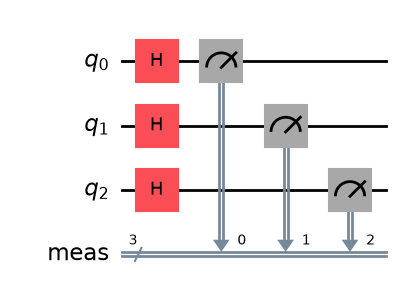

In [7]:
def ground_circuit(bitstring):
    qubits = QuantumRegister(NUM_BITS, name="q")
    bits = ClassicalRegister(NUM_BITS, name="meas")
    circuit = QuantumCircuit(qubits, bits, name="ground")
    for k in range(NUM_BITS):
        if bitstring[-1 - k] == "1":
            circuit.x(qubits[k])
    circuit.measure(qubits, bits)
    return circuit


def all_bitstrings_circuit():
    qubits = QuantumRegister(NUM_BITS, name="q")
    bits = ClassicalRegister(NUM_BITS, name="meas")
    circuit = QuantumCircuit(qubits, bits, name="all")
    circuit.h(qubits)                    # every bitstring with probability 1/8
    circuit.measure(qubits, bits)
    return circuit


circuits = {"ground": ground_circuit(ground), "all": all_bitstrings_circuit()}
circuits["all"].draw("mpl")

### Execution

The same pattern as Notebook 00: transpile, one PUB per circuit, one Sampler
job.

In [8]:
pubs = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    pubs[target.label] = [(pass_manager.run(c),) for c in circuits.values()]

results = {}
for target in targets:
    job = target.sampler.run(pubs[target.label], shots=SETTINGS.shots)
    results[target.label] = target.wait(job)

### Analysis

Each measured bitstring gets its cost from the diagonal of the Hamiltonian.
For the "ground" circuit every shot should cost 1. For the "all" circuit we
list the bitstrings by cost, confirm that the cheapest one returned is the
ground state, and average the cost over all shots. That average should be
near the mean of the diagonal, $56/8 = 7.0$, since every bitstring is equally
likely.

In [9]:
for label, result in results.items():
    if result is None:
        continue
    print(f"{label}, {SETTINGS.shots} shots")
    for name, pub_result in zip(circuits, result):
        counts = pub_result.data.meas.get_counts()
        average = sum(cost_of[b] * c for b, c in counts.items()) / SETTINGS.shots
        cheapest = min(counts, key=cost_of.get)
        print(f"  {name}: average cost over shots = {average:.3f}"
              f"   cheapest bitstring seen = {cheapest}")
        if name == "all":
            for b in sorted(counts, key=cost_of.get):
                print(f"      {b}  cost {cost_of[b]:5.1f}  counts {counts[b]}")

aer, 4096 shots
  ground: average cost over shots = 1.000   cheapest bitstring seen = 010
  all: average cost over shots = 7.090   cheapest bitstring seen = 010
      010  cost   1.0  counts 491
      100  cost   2.0  counts 529
      001  cost   3.0  counts 506
      000  cost   4.0  counts 492
      110  cost   7.0  counts 546
      011  cost   8.0  counts 493
      101  cost   9.0  counts 509
      111  cost  22.0  counts 530


Every shot of the "ground" circuit returned $010$ at cost 1. The "all"
circuit returned all 8 bitstrings, about 512 times each, and the cheapest of
them is the ground state. Its average cost is close to 7.0. Notebook 09 calls
an average like this the expectation value of the Hamiltonian and shows how
to measure it without listing bitstrings.

For three bits, trying every bitstring is cheap. The number of bitstrings
doubles with every added bit, so for the problems in Unit 3 it is not, and
the algorithms of Unit 2 are ways to make the cheap bitstrings much more
likely than the expensive ones.

## Exercises

1. Find the Pauli decomposition of $\left(\begin{smallmatrix}2&1\\1&0\end{smallmatrix}\right)$ with
   the trace formula, and check it against the guess at the start of the
   decomposition section.
2. Write the Hamiltonian of the penalty $(x_0 - x_1)^2$ as a sum of Pauli
   strings and check its diagonal.
3. Write the Hamiltonian of $x_0 x_1$ (the AND of two bits) as a sum of Pauli
   strings, in Qiskit labels. Which bitstring has eigenvalue 1?
4. In the experiment, change `LAMBDA` to 0.5 and rerun the Operator cell.
   What is the ground state now, and why is that a problem? For which values
   of $\lambda$ is every ground state a valid one-hot string? What happens at
   $\lambda = 1$?
5. Notebook 02 wrote CX (control 0, target 1) as $\bar n_0 + n_0 X_1$. Write
   it as a sum of Pauli strings in Qiskit labels, and check with the code in
   the solution.
6. True or false: the ground state of every Hamiltonian is a single
   bitstring. Give the reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   experiment on `ibm_rensselaer`. In the "ground" circuit, what fraction of
   shots is not $010$, and what costs do those shots have? Why does a large
   penalty weight $\lambda$ make the average cost more sensitive to hardware
   errors?
8. (hardware) In the "all" circuit on hardware, is every bitstring's fraction
   consistent with $p = 1/8$ under the scatter rule of Notebook 00?

## What you can now do

1. Find the Pauli decomposition of a matrix with $c_P = \mathrm{tr}(PM)/2^n$.
2. Turn a cost function of bits into a diagonal Hamiltonian with
   $x_k \to (I - Z_k)/2$, and read its ground state.
3. Explain, with the hopping operator, why a Hamiltonian with off-diagonal
   terms can have a superposition as its ground state.
4. Build Hamiltonians as `SparsePauliOp` objects and find their eigenvalues.

## Solutions

**Check, Pauli strings.** Qubit 2 is the leftmost of three letters and qubit
0 the rightmost: `"XIZ"`.

**Check, Pauli decomposition.** $\bar n = \mathrm{diag}(1, 0)$, so
$c_I = 1/2$, $c_Z = \mathrm{tr}(Z\bar n)/2 = 1/2$, and $c_X = c_Y = 0$:
$\bar n = (I + Z)/2$. **Check.** $n + \bar n = I$, as Notebook 01 requires.

**Check, Hamiltonians.** Expand: $x_0 + x_1 - 2x_0x_1$. Substitute and
collect as in Example 2: $\tfrac12(I - Z_1Z_0)$, the strings $I$ and $Z_1Z_0$.

**Check, off-diagonal terms.** $K$ swaps $|01\rangle$ and $|10\rangle$, so it
leaves their sum unchanged: eigenvalue $+1$.

**Exercise 1.** $c_I = \mathrm{tr}(M)/2 = 1$. $XM = \left(\begin{smallmatrix}1&0\\2&1\end{smallmatrix}\right)$,
trace 2, so $c_X = 1$. $YM = \left(\begin{smallmatrix}-i&0\\2i&i\end{smallmatrix}\right)$, trace 0,
so $c_Y = 0$. $ZM = \left(\begin{smallmatrix}2&1\\-1&0\end{smallmatrix}\right)$, trace 2, so
$c_Z = 1$. So $M = I + X + Z$, as guessed. **Check.**
`SparsePauliOp.from_operator(np.array([[2, 1], [1, 0]]))` gives
`['I', 'X', 'Z']` with coefficients 1.

**Exercise 2.** $(x_0 - x_1)^2 = x_0 + x_1 - 2x_0x_1$ (using $x^2 = x$).
Substitute: $\tfrac12(I - Z_0) + \tfrac12(I - Z_1) - \tfrac12(I - Z_1)(I - Z_0)$.
The constant is $\tfrac12 + \tfrac12 - \tfrac12 = \tfrac12$; the $Z_0$ and $Z_1$
coefficients are $-\tfrac12 + \tfrac12 = 0$; the $Z_1Z_0$ coefficient is
$-\tfrac12$. So $H_{\text{differ}} = \tfrac12(I - Z_1Z_0)$, with diagonal $(0, 1, 1, 0)$:
0 when the bits are equal and 1 when they differ.

**Exercise 3.** Substitute: $n_0 n_1 = \tfrac14(I - Z_0)(I - Z_1) = \tfrac14(I - Z_0 - Z_1 + Z_1Z_0)$.
In Qiskit labels: `II` $+0.25$, `IZ` $-0.25$, `ZI` $-0.25$, `ZZ` $+0.25$. The
eigenvalue on $|x_1x_0\rangle$ is $x_0x_1$, which is 1 only for $|11\rangle$.

**Exercise 4.** With $\lambda = 0.5$ the diagonal becomes
$(0.5, 3, 1, 4.5, 2, 5.5, 3.5, 8)$ for $000, 001, \ldots, 111$, so the ground
state is $|000\rangle$: choose nothing, at cost $\lambda$. That is not a valid
choice, so the "answer" is useless. The empty string costs $\lambda$, and the
cheapest valid string costs 1. Every other invalid string has at least two
bits set and costs at least $w_1 + w_2 + \lambda = 3 + \lambda$, more
than 1. So every ground state is valid exactly when $\lambda > 1$: the
penalty must be larger than the cheapest valid cost it competes with. At
$\lambda = 1$ the strings $000$ and $010$ tie at cost 1. Both are ground
states, and one of them is invalid, so the answer is ambiguous. Unit 3's
traveling-salesman notebook chooses its penalty weight by the same reasoning,
with a margin.

**Exercise 5.** Substitute $\bar n_0 = (I + Z_0)/2$ and $n_0 = (I - Z_0)/2$:
$\tfrac12(I + Z_0) + \tfrac12(I - Z_0) X_1 = \tfrac12(I + Z_0 + X_1 - X_1Z_0)$.
In Qiskit labels: `II`, `IZ`, `XI` with $+\tfrac12$ and `XZ` with $-\tfrac12$.
**Check.** This code returns the same four terms:

```python
from qiskit.circuit.library import CXGate
from qiskit.quantum_info import Operator, SparsePauliOp

print(SparsePauliOp.from_operator(Operator(CXGate())))
```

**Exercise 6.** False. It holds for diagonal Hamiltonians, where every
bitstring is an eigenvector. The hopping operator of Example 3 has the ground
state $\tfrac{1}{\sqrt2}(|01\rangle - |10\rangle)$, a superposition.

**Exercise 7.** Expect a few percent of the shots on other bitstrings, mostly
those that differ from $010$ in one bit: $000$ (cost 4), $011$ (cost 8) and
$110$ (cost 7). Each of these is invalid and carries a penalty of at least
$\lambda$, so the average cost rises above 1 by roughly (fraction of wrong
shots) times (their extra cost above 1). Each extra cost grows one for one
with $\lambda$: going from $\lambda = 4$ to $\lambda = 8$ raises it from 3 to 7
for $000$, from 7 to 11 for $011$, and from 6 to 10 for $110$. So the same
hardware errors raise the average 1.6 to 2.3 times as much, even though the
ground state is the same. The readout effect of Notebook 00 (a 1 read as 0)
makes $000$ the most common wrong string, which puts the factor near the top
of that range.

**Exercise 8.** For $p = 1/8$ and $N = 4096$, the scatter is
$\sqrt{0.125 \times 0.875 / 4096} \approx 0.005$. By the scatter rule of
Notebook 00, expect most fractions within twice that of 0.125, about 0.115 to
0.135, and treat a difference of more than three times the scatter, 0.015, as
a real effect. A systematic tilt toward bitstrings with more 0s points to the
readout effect of Notebook 00: a 1 is misread as 0 more often than the
reverse.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| Pauli string | a tensor product with one of $I$, $X$, $Y$, $Z$ on each qubit |
| Qiskit Pauli label | the text form of a Pauli string; the rightmost letter acts on qubit 0 |
| Pauli decomposition | $M = \sum_P c_P P$ with $c_P = \mathrm{tr}(PM)/2^n$ |
| Hermitian | equal to its own conjugate transpose; its Pauli coefficients are real |
| `SparsePauliOp` | Qiskit's weighted sum of Pauli strings |
| Hamiltonian | a Hermitian operator whose eigenvalues are the energies or costs of a problem |
| ground state | the eigenvector of a Hamiltonian with the lowest eigenvalue |
| ground-state energy | that lowest eigenvalue |
| diagonal Hamiltonian | a Hamiltonian with a diagonal matrix; every bitstring is an eigenvector, with its cost as eigenvalue |
| hopping operator | $a_0^\dagger a_1 + a_1^\dagger a_0 = \tfrac12(X_0X_1 + Y_0Y_1)$, which moves a 1 between two bits |